# FFM_3_6 — mesh2z 用完整网格重做：不采样、逐三角形精确积分

**为什么有这个 notebook。** FFM_3_2_1 … 3_5 的输入是从网格上随机采的 2 万点（`mesh2z_samples`）。
10-06 的保真性检查（`notes/mesh2z_audit_2026-10-06/AUDIT_CN.md`）确认采样、镜像、打包都没有转换错误，
但指出几处问题，使「mesh2z 失败」不能推广到完整网格。这里逐条处理：

| 审计指出的问题 | FFM_3_5 | FFM_3_6 |
|---|---|---|
| 输入是 2 万个随机点；同一网格换采样种子，RFF 特征就变（同人重采样距离 = 人与人距离的 12–23%） | 20k 随机点 | 上传**完整 STL**（200 人，原样字节，逐文件 SHA-256）。RFF 均值嵌入对**每个三角形用闭式解精确积分**，几何量用面积测度下的**精确分位数** → 没有采样噪声 |
| MLP 只预测前 64 个主成分（训练方差 82%，验证集 oracle R² 0.63），ridge 预测完整 z | 64 PC | **全部主成分**：MLP 与 ridge 输出空间相同；另报「oracle 投影」一行 |
| 特征块权重与 FFM_3_2_1 不同（9 个简单量只占 0.35% 的列） | 逐列标准化 | **按块加权**（与 3_2_1 相同）；逐列版本保留为对照 |
| 有限的全局描述符 | M = 256 | 另报 **M = 1024** 和 **加法向**（currents：∫ n·e^{iκ·x} dA）两个版本 |
| 本地缓存可能过期；读 npz 不校验来源 | 见到 manifest 就复用 | zip 的 SHA-256 写在 Cell 0；每个 STL 读入时校验 SHA-256；特征缓存按内容指纹命名 |
| 引言说 5 个种子，实际 1 个 | | 只用 `CFG['SEEDS']`（默认 `[0]`） |

**仍然消除不了的限制**（写结论时必须说）
- 源网格是 SONICOM 的 `*_preprocessed.stl`：整理方已做 Frankfurt 对齐、截断、平滑、去发；原始 3DSCAN 不在我们手里。
- 耳道位置来自 Mesh2HRTF 仿真的 ReceiverPosition，不是对实测麦克风位置的独立校准。
- 任何有限描述符都是压缩。这里能做的是：消除采样噪声，并检查描述符加大、加入朝向之后结论是否改变。

**划分**：与 FFM_3_5 完全相同（同一 `SPLIT_SEED`、同一 164 开发 + 36 锁定）。Drive 上有 3_5 的 checkpoint 时，Cell 8 逐人核对。
锁定的 36 人：只读网格、算几何特征；**z 和 HRTF 在 TEST 格之前不读取**。

**事先写下的读数**（跑之前定死，不看结果再加）
1. 采样噪声：ridge(exact) 对 ridge(MC 20k，3 个种子) —— 验证 dB 之差，按人配对 bootstrap。
2. 特征权重：ridge 按块 对 逐列。
3. 描述符：exact (M=256) 对 M=1024、对 +法向。
4. 非线性：同一特征、同一输出空间下，MLP 对 ridge。
5. **停止规则**：所有模型行的验证 R²(z) < 0.10 → 结论不变（可检测、不可用），而且这个结论现在覆盖「完整网格、无采样」的输入。

α 和 epoch 都在验证集上选，验证分数偏乐观 —— 对一个负结论，这是保守的方向。

**测试集**：`RUN_TEST = False`。36 个锁定的人只能用一次；本 notebook 与 FFM_3_5 共用标记文件，一边用过，另一边会拒绝。

---

## 上传（只做一次）

本地已经用 `mesh2z/pack_full_meshes.py` 打好包（逐文件核对过 SHA-1 与 3_5 用的源文件相同、耳道位置相同）：

| 文件 | 大小 |
|---|---|
| `~/Documents/26S1/ELEC5020/SONICOM/sonicom_full_meshes.zip` | 2.96 GB（200 个 STL 原样 4.87 GB，deflate） |
| `~/Documents/26S1/ELEC5020/SONICOM/sonicom_full_meshes.zip.sha256` | 哈希 |

把这两个文件放到 Drive 的 **`MyDrive/ELEC5020/SONICOM/`**（和 `mesh2z_samples.zip` 同一个文件夹）。
Cell 0 会核对 zip 的 SHA-256；上传不完整或传错文件会直接报错。

In [ ]:
# ==========================================================================
# Cell 0 — 环境 · 路径 · 把完整网格 zip 复制到本地并核对 SHA-256
# ==========================================================================
import os, sys, io, json, csv, zipfile, hashlib, time, math, copy, shutil, warnings
warnings.filterwarnings('ignore')
import numpy as np

MESH_ZIP_SHA256 = 'a73401a12d92643d9c6c80a66cb443e9983b4880d53b78924fece42f7c124f8d'     # pack_full_meshes.py 的输出；zip 不是这一个就停

def sha256_file(p, block=1 << 24):
    h = hashlib.sha256()
    with open(p, 'rb') as f:
        for b in iter(lambda: f.read(block), b''): h.update(b)
    return h.hexdigest()

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE = '/content/drive/MyDrive'
    SAVE_DIR = f'{DRIVE}/HRTF_Checkpoints'
    os.system('pip install healpy -q')
    PATHS = dict(
        ckpt        = f'{SAVE_DIR}/FFM26_best.pth',
        mesh_latent = f'{SAVE_DIR}/mesh2z_sonicom_latents_v1.npz',      # FFM_3_1 的导出（z、划分）
        meshes      = f'{DRIVE}/ELEC5020/SONICOM/sonicom_full_meshes.zip',
        sonicom     = f'{DRIVE}/ELEC5020/SONICOM.zip',                  # 实测 HRTF（解码后比 dB 用）
    )
    OUT_DIR = f'{SAVE_DIR}/mesh2z_fullmesh_v1'
    LOCAL = '/content/local_data'; os.makedirs(LOCAL, exist_ok=True)
    def stage(src, expect=None):
        """复制到 Colab 本地盘。给了 expect 就核对 SHA-256：本地已有但哈希不对 → 删掉重新复制（不会用到过期的副本）"""
        dst = os.path.join(LOCAL, os.path.basename(src))
        if os.path.exists(dst) and expect and sha256_file(dst) != expect:
            print(f'本地的 {os.path.basename(dst)} 与期望的哈希不同，重新复制', flush=True); os.remove(dst)
        if not os.path.exists(dst):
            t0 = time.time(); print(f'复制 {os.path.basename(src)} → 本地 …', flush=True)
            shutil.copy2(src, dst + '.part'); os.replace(dst + '.part', dst)
            print(f'  {os.path.getsize(dst)/1e9:.2f} GB，{time.time()-t0:.0f} s', flush=True)
        return dst
    PATHS['ckpt'] = stage(PATHS['ckpt']); PATHS['mesh_latent'] = stage(PATHS['mesh_latent'])
    if os.path.exists(PATHS['meshes']): PATHS['meshes'] = stage(PATHS['meshes'], MESH_ZIP_SHA256)
else:
    H = os.path.expanduser('~/Documents'); R = f'{H}/26S2/ELEC5021/hrtf-GitHub'
    PATHS = dict(
        ckpt        = os.environ.get('FFM26_CKPT', f'{R}/results/FFM26_best.pth'),
        mesh_latent = f'{R}/mesh2z/output/mesh2z_sonicom_latents_v1.npz',
        meshes      = f'{H}/26S1/ELEC5020/SONICOM/sonicom_full_meshes.zip',
        sonicom     = f'{H}/26S1/ELEC5020/SONICOM',
    )
    OUT_DIR = os.environ.get('FULLMESH_OUT', f'{R}/mesh2z/output/mesh2z_fullmesh_v1')
    SAVE_DIR = os.path.dirname(OUT_DIR)
os.makedirs(OUT_DIR, exist_ok=True)
for k, p in PATHS.items():
    print(f'{k:12s} {"OK " if os.path.exists(p) else "★缺失"} {p}')
assert all(os.path.exists(p) for p in PATHS.values()), '先放好缺失的文件（完整网格 zip 的上传方法见最上面）'
t0 = time.time(); h = sha256_file(PATHS['meshes'])
assert h == MESH_ZIP_SHA256, f'{PATHS["meshes"]} 的 SHA-256 是 {h}，不是打包时的 {MESH_ZIP_SHA256}：上传不完整或不是同一个文件'
print(f'完整网格 zip 的 SHA-256 核对通过（{time.time()-t0:.0f} s）')

Mounted at /content/drive
复制 FFM26_best.pth → 本地 …
  0.41 GB，10 s
复制 mesh2z_sonicom_latents_v1.npz → 本地 …
  0.03 GB，2 s
复制 sonicom_full_meshes.zip → 本地 …
  2.96 GB，81 s
ckpt         OK  /content/local_data/FFM26_best.pth
mesh_latent  OK  /content/local_data/mesh2z_sonicom_latents_v1.npz
meshes       OK  /content/local_data/sonicom_full_meshes.zip
sonicom      OK  /content/drive/MyDrive/ELEC5020/SONICOM.zip
完整网格 zip 的 SHA-256 核对通过（2 s）


In [ ]:
# ==========================================================================
# Cell 1 — 配置（★ 跑之前定死）
# ==========================================================================
CFG = dict(
    DID        = 2,                                  # SONICOM 在 FFM26 里的数据集编号
    VAL_FRAC   = 0.20, SPLIT_SEED = 0,               # 与 FFM_3_5 相同 → 同一批 train / val 人
    # ---- 几何（与 FFM_3_2_1 / 3_5 的最好配置相同，只是改成精确计算）
    SIGMAS     = [0.005, 0.01, 0.02, 0.05, 0.1],     # mm⁻¹
    M          = 256,                                # 主特征：每个 σ 256 个频率（与 3_5 相同的随机方向）
    M_BIG      = 1024,                               # 描述符对照：前 256 个就是 M 的那些
    Z_CUT      = -75.0,                              # 头部几何量只用 z > Z_CUT 的表面（精确切开）
    PINNA_DY   = 3.0,                                # 耳廓「伸出」= 耳道坐标 y > 3 mm 的表面（精确切开）
    MC_N       = 20000, MC_SEEDS = [0, 1, 2],        # 对照：在同一完整网格上随机采 2 万点（= 3_5 的做法）
    # ---- 要比较的特征集（ridge 全部跑；MLP 只跑 MLP_SETS）
    FEATURE_SETS = ['exact', 'exact_colweight', 'exact_M1024', 'exact+normals', 'mc20k_s0', 'mc20k_s1', 'mc20k_s2'],
    PRIMARY    = 'exact',
    MLP_SETS   = ['exact'],
    K_PC       = None,                               # None = 训练集 z 的全部主成分 → MLP 与 ridge 输出空间相同
    HIDDEN=(256, 128), DROPOUT=0.1, LR=1e-3, WD=1e-2, BATCH=16, EPOCHS=500, LR_MIN=1e-5, GRAD_CLIP=1.0,
    SEEDS      = [0],                                # 以后加种子：[0, 1, 2]；已训练的从 checkpoint 载入
    ALPHA_REL  = list(np.logspace(-4, 5, 37)),       # α = c · trace(AAᵀ)/n，与 FFM_3_2_1 相同的相对网格
    NOTCH_HZ   = (6000, 12000), STOP_R2 = 0.10, N_BOOT = 2000,
    PRINT_EVERY = 10, SAVE_EVERY = 10,
    SMOKE_N    = None,                               # 本地冒烟测试：只用前 N 个开发受试者（Colab 上保持 None）
    RUN_TEST   = False,                              # ★ 只在决定不再改任何东西之后才改成 True，且只跑一次
)
if not IN_COLAB and os.environ.get('FULLMESH_SMOKE'):
    CFG.update(SMOKE_N=int(os.environ['FULLMESH_SMOKE']), EPOCHS=int(os.environ.get('FULLMESH_EPOCHS', 3)))
print(json.dumps({k: v for k, v in CFG.items() if k != 'ALPHA_REL'}, indent=1, ensure_ascii=False))

{
 "DID": 2,
 "VAL_FRAC": 0.2,
 "SPLIT_SEED": 0,
 "SIGMAS": [
  0.005,
  0.01,
  0.02,
  0.05,
  0.1
 ],
 "M": 256,
 "M_BIG": 1024,
 "Z_CUT": -75.0,
 "PINNA_DY": 3.0,
 "MC_N": 20000,
 "MC_SEEDS": [
  0,
  1,
  2
 ],
 "FEATURE_SETS": [
  "exact",
  "exact_colweight",
  "exact_M1024",
  "exact+normals",
  "mc20k_s0",
  "mc20k_s1",
  "mc20k_s2"
 ],
 "PRIMARY": "exact",
 "MLP_SETS": [
  "exact"
 ],
 "K_PC": null,
 "HIDDEN": [
  256,
  128
 ],
 "DROPOUT": 0.1,
 "LR": 0.001,
 "WD": 0.01,
 "BATCH": 16,
 "EPOCHS": 500,
 "LR_MIN": 1e-05,
 "GRAD_CLIP": 1.0,
 "SEEDS": [
  0
 ],
 "NOTCH_HZ": [
  6000,
  12000
 ],
 "STOP_R2": 0.1,
 "N_BOOT": 2000,
 "PRINT_EVERY": 10,
 "SAVE_EVERY": 10,
 "SMOKE_N": null,
 "RUN_TEST": false
}


In [ ]:
# ==========================================================================
# Cell 2 - 模型定义（与 FFM_2_3 / FFM_2_6 逐字相同，构建时复制进来）
# ==========================================================================
import numpy as np
import torch
import torch.nn as nn
import healpy as hp


# ---------------------------------------------- spherical convolution
class OSLOConv(nn.Module):
    """Anisotropic convolution on HEALPix: each pixel plus its 8 neighbours, 9 independent weights."""
    def __init__(self, in_channels, out_channels, nside=16):
        super().__init__()
        self.npix = hp.nside2npix(nside)
        neighbors = hp.get_all_neighbours(nside, np.arange(self.npix))
        rf = np.concatenate([neighbors, np.arange(self.npix)[np.newaxis, :]], axis=0)
        rf[rf == -1] = self.npix
        self.register_buffer('neighborhood', torch.tensor(rf, dtype=torch.int64))
        self.weight = nn.Parameter(torch.empty(out_channels, in_channels, 9))
        self.bias = nn.Parameter(torch.empty(out_channels))
        nn.init.kaiming_uniform_(self.weight, a=np.sqrt(5))
        nn.init.zeros_(self.bias)

    def forward(self, x):
        B, C, _ = x.shape
        pad = torch.zeros(B, C, 1, device=x.device, dtype=x.dtype)
        g = torch.cat([x, pad], dim=2)[:, :, self.neighborhood]
        return torch.einsum('bcqn,ocq->bon', g, self.weight) + self.bias.view(1, -1, 1)


class OSLOResBlock(nn.Module):
    """Frequency-isolated residual block, operating on (B*F, C, N).
    * v2: ReLU -> GELU. HRTF log-magnitude is bipolar (negative means attenuation), so
      ReLU truncates the negative half; GELU is smooth, keeps negatives, and matches the fc layers."""
    def __init__(self, in_channels, out_channels, nside=16, num_groups=8):
        super().__init__()
        self.shortcut = (nn.Conv1d(in_channels, out_channels, 1)
                         if in_channels != out_channels else nn.Identity())
        self.conv1 = OSLOConv(in_channels, out_channels, nside)
        self.gn1 = nn.GroupNorm(num_groups, out_channels)
        self.conv2 = OSLOConv(out_channels, out_channels, nside)
        self.gn2 = nn.GroupNorm(num_groups, out_channels)
        self.act = nn.GELU()

    def forward(self, x):
        res = self.shortcut(x)
        out = self.act(self.gn1(self.conv1(x)))
        out = self.gn2(self.conv2(out))
        return self.act(out + res)


# ---------------------------------------------- per-dataset FiLM
class DatasetFiLM(nn.Module):
    """Learn one PER-FREQUENCY scale/shift curve for each dataset.

    ** Constraint 1: frequency only, NEVER direction.
      A per-frequency affine map is one EQ curve (93 dof per dataset). All it can absorb is
      "colouration common to the whole dataset and independent of direction" — loudspeaker and
      microphone response, equalisation convention, overall level. By construction it CANNOT
      express a direction-dependent difference, so population anatomy (ear-size distributions
      differ across databases) must still live in z. Contrast: subtracting a per-database mean
      over (frequency x direction) is 3072x93 dof, enough to remove the real population structure
      as well — exactly the wrong direction Craig pointed at. A factor of 3072 in expressive power.

    ** Constraint 2: centre across datasets.
      Without centring, log_gamma/beta learn a global EQ that cancels against the network's own
      output gain — a redundant degree of freedom. After the cross-database mean is removed FiLM
      expresses only RELATIVE differences; the absolute part stays in the network. Exactly the identity when num_datasets=1.
    """
    def __init__(self, num_datasets, num_bins):
        super().__init__()
        self.num_datasets = num_datasets
        self.log_gamma = nn.Parameter(torch.zeros(num_datasets, num_bins))
        self.beta = nn.Parameter(torch.zeros(num_datasets, num_bins))

    def params(self, dataset_id):
        lg = self.log_gamma - self.log_gamma.mean(0, keepdim=True)
        bt = self.beta - self.beta.mean(0, keepdim=True)
        return torch.exp(lg[dataset_id]).unsqueeze(-1), bt[dataset_id].unsqueeze(-1)

    def forward(self, x, dataset_id):
        g, b = self.params(dataset_id)
        return x * g + b

    def inverse(self, x, dataset_id):
        g, b = self.params(dataset_id)
        return (x - b) / g


# ---------------------------------------------- encoder / decoder

class Isolated_OSLO_Encoder(nn.Module):
    """Encode each frequency bin independently -> latent (B, F, latent_dim)"""
    def __init__(self, nside=16, latent_dim_per_freq=64):
        super().__init__()
        self.npix = hp.nside2npix(nside)
        self.latent_dim = latent_dim_per_freq
        self.enc1 = OSLOResBlock(1, 16, nside)
        self.enc2 = OSLOResBlock(16, 32, nside)
        self.fc_encode = nn.Sequential(
            nn.Flatten(), nn.Linear(32 * self.npix, 512), nn.GELU(),
            nn.Linear(512, self.latent_dim))

    def forward(self, x):
        B, F, N = x.shape
        z = self.fc_encode(self.enc2(self.enc1(x.reshape(B * F, 1, N))))
        return z.reshape(B, F, self.latent_dim)


class Conditioned_OSLO_Decoder(nn.Module):
    """FFM frequency-conditioned decoder + per-dataset FiLM on the output"""
    def __init__(self, nside=16, latent_dim_per_freq=64, freq_embed_dim=32,
                 num_datasets=1, num_bins=93):
        super().__init__()
        self.npix = hp.nside2npix(nside)
        self.latent_dim = latent_dim_per_freq
        self.freq_embed_dim = freq_embed_dim
        self.ffm_B = nn.Parameter(torch.randn(freq_embed_dim // 2))
        self.fc_decode = nn.Sequential(
            nn.Linear(self.latent_dim + freq_embed_dim, 512), nn.GELU(),
            nn.Linear(512, 32 * self.npix))
        self.dec1 = OSLOResBlock(32, 16, nside)
        self.dec_final = OSLOConv(16, 1, nside)
        self.film = DatasetFiLM(num_datasets, num_bins)

    def get_freq_embedding(self, num_freqs, device):
        f = torch.arange(num_freqs, device=device).float() / (num_freqs - 1)
        proj = 2 * np.pi * f.unsqueeze(1) * self.ffm_B.unsqueeze(0)
        return torch.cat([torch.sin(proj), torch.cos(proj)], dim=1)

    def forward(self, z, dataset_id=None):
        B, F, _ = z.shape
        fe = self.get_freq_embedding(F, z.device).unsqueeze(0).expand(B, -1, -1)
        h = torch.cat([z, fe], dim=-1).reshape(B * F, -1)
        h = self.fc_decode(h).reshape(B * F, 32, self.npix)
        out = self.dec_final(self.dec1(h)).reshape(B, F, self.npix)
        if dataset_id is not None:
            out = self.film(out, dataset_id)
        return out


class FFM_OSLO_Autoencoder(nn.Module):
    """One SHARED-parameter inverse FiLM at the encoder input — zero extra parameters.

    With FiLM on the decoder output only, the colouration stays in x, the encoder takes it in, and it
    lands in z — but z is exactly what the downstream geometry->latent stage needs. Output-side FiLM
    only makes the reconstruction loss line up; it does not clean z.

    Here     x_norm = (x - beta)/gamma        <- remove colouration
             z      = encoder(x_norm)
             out    = gamma * decoder(z) + beta   <- back to the original space, loss still on raw

    The SAME FiLM parameters are used. Together with centring this also kills the trivial degenerate
    direction "scale gamma up, scale the network down". Set tie_encoder_film=False to disable.
    """
    def __init__(self, nside=16, latent_dim_per_freq=64, freq_embed_dim=32,
                 num_datasets=1, num_bins=93, tie_encoder_film=True):
        super().__init__()
        self.encoder = Isolated_OSLO_Encoder(nside, latent_dim_per_freq)
        self.decoder = Conditioned_OSLO_Decoder(nside, latent_dim_per_freq,
                                                freq_embed_dim, num_datasets, num_bins)
        self.tie_encoder_film = tie_encoder_film

    def forward(self, x, dataset_id=None):
        if dataset_id is not None and self.tie_encoder_film:
            x = self.decoder.film.inverse(x, dataset_id)
        z = self.encoder(x)
        return self.decoder(z, dataset_id), z


print('model defined (FFM + FiLM)')

model defined (FFM + FiLM)


In [ ]:
# ==========================================================================
# Cell 3 — 公共工具：AE 解码、HRTF 读取、指标、目标 PCA、按块加权、ridge、MLP、测试集保护
# ==========================================================================
import torch, torch.nn as nn, healpy as hp
import matplotlib.pyplot as plt
torch.backends.cuda.matmul.allow_tf32 = False      # ★ 相位 κ·x 可达 ~100 rad：TF32 只有 10 位尾数，会毁掉 RFF
torch.backends.cudnn.allow_tf32 = False
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ck = torch.load(PATHS['ckpt'], map_location=device, weights_only=False)
N_BINS = ck['model_state_dict']['decoder.film.beta'].shape[1]
AE = FFM_OSLO_Autoencoder(nside=16, latent_dim_per_freq=64, freq_embed_dim=32, num_datasets=4,
                          num_bins=N_BINS, tie_encoder_film=True).to(device)
AE.load_state_dict(ck['model_state_dict']); AE.eval(); del ck
FREQS = np.arange(N_BINS) * 44100 / 256
NOTCH = (FREQS >= CFG['NOTCH_HZ'][0]) & (FREQS <= CFG['NOTCH_HZ'][1])
_th, _ph = hp.pix2ang(16, np.arange(3072)); MIRROR = hp.ang2pix(16, _th, (-_ph) % (2 * np.pi))
print(f'AE 载入 | {N_BINS} bins | {device}')

def find_dir(root, target):
    c = []
    for dp, _, fns in os.walk(root):
        if '__MACOSX' in dp: continue
        if os.path.basename(dp) == target: c.append((sum(f.endswith('.npy') for f in fns), dp))
    c.sort(reverse=True); return c[0][1] if c else None

def npy_dirs(src, name):
    if src.endswith('.zip'):
        out = f'/content/dataset/{name}'; os.makedirs(out, exist_ok=True)
        if find_dir(out, 'npy_left') is None:
            t0 = time.time(); print(f'解压 {os.path.basename(src)} 到 {out} …（第一次要几分钟）', flush=True)
            with zipfile.ZipFile(src) as z: z.extractall(out)
            print(f'  解压完成，{time.time()-t0:.0f} s', flush=True)
        src = out
    d = (find_dir(src, 'npy_left'), find_dir(src, 'npy_right')); assert all(d), f'{name}: 找不到 npy_left/right'
    return d

def load_ear(dirs, sid, side):
    x = np.load(os.path.join(dirs[side], f"{sid}_{('left', 'right')[side]}_full.npy")).astype(np.float32)[:N_BINS]
    return x[:, MIRROR] if side == 1 else x

@torch.no_grad()
def decode(Zrows, did=CFG['DID']):
    out = np.zeros((len(Zrows), N_BINS, 3072), np.float32)
    for b in range(0, len(Zrows), 32):
        z = torch.from_numpy(Zrows[b:b + 32].reshape(-1, N_BINS, 64).astype(np.float32)).to(device)
        out[b:b + 32] = AE.decoder(z, torch.full((len(z),), did, device=device)).cpu().numpy()
    return out

def hrtf_metrics(P, X, side, base_db=None, rec_db=None):
    """P, X: (n_ears, 93, 3072)。pooled = 所有耳 × bin × 方向（与 evaluate() 同口径）；ear_mse 用于按人配对 bootstrap"""
    e2 = (P - X) ** 2; d = np.sqrt(e2.mean(1))
    out = dict(db=float(np.sqrt(e2.mean())), db_notch=float(np.sqrt(e2[:, NOTCH].mean())), lsd=float(d.mean()),
               ear_mse=e2.mean((1, 2)).astype(np.float64))
    ranks = []
    for s in (0, 1):                                  # 在本分区内、同侧耳里认人
        r = np.flatnonzero(side == s); a = P[r].reshape(len(r), -1); b = X[r].reshape(len(r), -1)
        d2 = (a * a).sum(1)[:, None] + (b * b).sum(1)[None] - 2 * a @ b.T
        ranks.append((d2 < d2.diagonal()[:, None]).sum(1) + 1)
    rk = np.concatenate(ranks); out['rank1'] = float(np.mean(rk == 1)); out['chance'] = 2 / len(P)
    if base_db is not None and rec_db is not None:
        out['recovered'] = (base_db - out['db']) / (base_db - rec_db)
    return out

def r2z(pred, Y, my):
    return float(1 - ((Y - pred) ** 2).sum() / ((Y - my) ** 2).sum())

class TargetPCA:
    """z -> 训练集主成分得分 / 一个全局 scale。k=None：全部主成分（= ridge 预测所在的空间）。inverse 必须把 scale 乘回去"""
    def __init__(self, Ytr, k=None):
        self.my = Ytr.mean(0); U, s, Vt = np.linalg.svd(Ytr - self.my, full_matrices=False)
        r = int((s > s[0] * 1e-9).sum()); k = r if k is None else min(k, r); self.V = Vt[:k].T
        T = (Ytr - self.my) @ self.V; self.scale = float(np.sqrt((T ** 2).sum(1).mean()))
    def forward(self, Y): return (Y - self.my) @ self.V / self.scale
    def inverse(self, T): return self.my + (T * self.scale) @ self.V.T

class BlockInput:
    """训练集上 z-score 每一列，再按块加权，使每块的总方差相同 —— 等价于 FFM_3_2_1 的 Gram = Σ_b Xz_b Xz_bᵀ / d_b。
    整体再乘 √(D / 块数)，平均每列方差仍为 1（对 MLP 的初始化友好；ridge 的 α 是相对的，不受影响）。
    blocks=None：FFM_3_5 的做法，所有列一视同仁。"""
    def __init__(self, Xtr, blocks):
        self.mx = Xtr.mean(0); sd = Xtr.std(0); keep = sd > 1e-12 * max(sd.max(), 1e-300)
        self.sx = np.where(keep, sd, 1.0); D = int(keep.sum())
        if blocks is None: w = np.ones(Xtr.shape[1])
        else:
            w = np.zeros(Xtr.shape[1])
            for sl in blocks: w[sl] = math.sqrt(D / (len(blocks) * max(int(keep[sl].sum()), 1)))
        self.w = np.where(keep, w, 0.0); self.blocks = None if blocks is None else [(b.start, b.stop) for b in blocks]
    def __call__(self, X): return (X - self.mx) / self.sx * self.w

def ridge_val(Atr, Ytr, Ava, Yva, grid_rel):
    """解析解 ridge（输入已居中、加权）；α = c·trace(AAᵀ)/n，c 由验证集 z 空间误差选"""
    my = Ytr.mean(0); U, s, Vt = np.linalg.svd(Atr, full_matrices=False); UtY = U.T @ (Ytr - my)
    sc = float((s ** 2).sum() / len(Atr)); sse = []
    for c in grid_rel:
        W = Vt.T @ ((s / (s ** 2 + c * sc))[:, None] * UtY); sse.append(((Ava @ W + my - Yva) ** 2).sum())
    i = int(np.argmin(sse)); W = Vt.T @ ((s / (s ** 2 + grid_rel[i] * sc))[:, None] * UtY)
    return (lambda A: A @ W + my), float(grid_rel[i]), i

class MLP(nn.Module):
    def __init__(self, d_in, hidden, k, p):
        super().__init__(); L, d = [], d_in
        for h in hidden: L += [nn.Linear(d, h), nn.GELU(), nn.Dropout(p)]; d = h
        L.append(nn.Linear(d, k)); self.net = nn.Sequential(*L)
    def forward(self, x): return self.net(x)

def atomic_save(obj, path):
    tmp = path + '.tmp'; torch.save(obj, tmp); os.replace(tmp, path)

# SONICOM 的 36 个锁定受试者只能用一次：FFM_3_5 与 FFM_3_6 共用这些标记
TEST_MARKS = [os.path.join(SAVE_DIR, 'TEST_SPENT_SONICOM_locked36.json'),
              os.path.join(SAVE_DIR, 'geometry2z_tvt_v1', 'TEST_SPENT_mesh.json'),
              os.path.join(SAVE_DIR, 'geometry2z_tvt_v2', 'TEST_SPENT_mesh.json')]
def guard_test():
    used = [p for p in TEST_MARKS if os.path.exists(p)]
    assert not used, f'SONICOM 的锁定测试集已经用过：{used}。不要再评估第二次。'
print('工具就绪')

AE 载入 | 93 bins | cuda
工具就绪


In [ ]:
# ==========================================================================
# Cell 4 — 完整网格的几何工具（全部是确定性的：没有随机采样）
#
# ① 读 STL：原样的 float32 顶点，不焊接、不平滑、不重网格化
# ② 耳部裁剪：三角面质心距耳道 < 45 mm（与 sample_meshes.py 的定义相同）；右耳 y → −y 并反转顶点顺序（法向仍朝外）
# ③ 半空间裁剪（y > 3 mm、z > −75 mm）：把三角形精确切开，不是按点筛选
# ④ 面积分布的分位数：一个线性函数在三角形上的面积分布是三角分布 → 混合分布的分位数可以精确求
# ⑤ RFF 均值嵌入 = (1/面积) ∫_S exp(iκ·x) dA，对每个三角形用闭式解精确积分（不采点）
# ==========================================================================
FLIP = np.array([1.0, -1.0, 1.0])
EAR_R = 45.0

def read_stl(b):
    """binary STL bytes -> (T, 3, 3) float32 顶点，原样"""
    n = int(np.frombuffer(b, '<u4', count=1, offset=80)[0])
    if len(b) != 84 + 50 * n: raise ValueError(f'不是 binary STL：头部写 {n} 个三角形，文件 {len(b)} 字节')
    dt = np.dtype([('n', '<f4', 3), ('v', '<f4', (3, 3)), ('attr', '<u2')])
    return np.frombuffer(b, dt, count=n, offset=84)['v']

def tri_area(Q):
    return 0.5 * np.linalg.norm(np.cross(Q[:, 1] - Q[:, 0], Q[:, 2] - Q[:, 0]), axis=1)

def ear_crop(V, canal, side):
    """质心在耳道 EAR_R 以内的三角面，平移到耳道为原点；右耳镜像到左耳坐标系（顶点顺序反转，法向仍朝外）"""
    V64 = V.astype(np.float64)
    idx = np.flatnonzero(np.linalg.norm(V64.mean(1) - canal, axis=1) < EAR_R)
    Q = V64[idx] - canal
    return (Q * FLIP)[:, [0, 2, 1]] if side == 1 else Q

def clip_halfspace(Q, w, h):
    """每个三角形在 x·w > h 一侧的部分，精确切开（每个三角形变成 0、1 或 2 个三角形）"""
    s = Q @ np.asarray(w, float) - h; ins = s > 0; k = ins.sum(1)
    out = [Q[k == 3]]
    for kk in (1, 2):
        sel = np.flatnonzero(k == kk)
        if not len(sel): continue
        odd = np.argmax(ins[sel], 1) if kk == 1 else np.argmin(ins[sel], 1)   # 单独在一侧的那个顶点
        r = (odd[:, None] + np.arange(3)) % 3                                 # 轮换到第 0 位（不改变朝向）
        q = np.take_along_axis(Q[sel], r[:, :, None], 1); ss = np.take_along_axis(s[sel], r, 1)
        P0, P1, P2 = q[:, 0], q[:, 1], q[:, 2]
        X1 = P0 + (P1 - P0) * (ss[:, :1] / (ss[:, :1] - ss[:, 1:2]))
        X2 = P0 + (P2 - P0) * (ss[:, :1] / (ss[:, :1] - ss[:, 2:3]))
        out += [np.stack([P0, X1, X2], 1)] if kk == 1 else [np.stack([X1, P1, P2], 1), np.stack([X1, P2, X2], 1)]
    return np.concatenate(out)

def area_quantiles(Q, c, qs, iters=64):
    """坐标 x·c 在三角形集合 Q 的面积测度下的精确分位数。
    线性函数在均匀三角形上服从三角分布(最小, 中间, 最大)，所以 CDF 是各三角形的分段二次 CDF 按面积加权。
    只有跨过 t 的三角形贡献分数部分；它们在按最小值排序的数组里是一段连续区间，所以每次求值很快。"""
    v = np.sort(Q @ np.asarray(c, float), axis=1); w = tri_area(Q); keep = w > 0
    a, m, b, w = v[keep, 0], v[keep, 1], v[keep, 2], w[keep]; W = w.sum(); E = float((b - a).max())
    oa = np.argsort(a, kind='stable'); a, m, b, w = a[oa], m[oa], b[oa], w[oa]
    ob = np.argsort(b, kind='stable'); bs = b[ob]; cwb = np.concatenate([[0.0], np.cumsum(w[ob])])
    def cdf(t):
        full = cwb[np.searchsorted(bs, t, side='right')]               # b ≤ t：整块面积
        lo, hi = np.searchsorted(a, t - E, side='right'), np.searchsorted(a, t, side='left')
        aa, mm, bb, ww = a[lo:hi], m[lo:hi], b[lo:hi], w[lo:hi]
        s = bb > t; aa, mm, bb, ww = aa[s], mm[s], bb[s], ww[s]         # a < t < b：跨过 t 的三角形
        up = np.where(t <= mm, (t - aa) ** 2 / np.where((bb - aa) * (mm - aa) > 0, (bb - aa) * (mm - aa), 1.0),
                      1 - (bb - t) ** 2 / np.where((bb - aa) * (bb - mm) > 0, (bb - aa) * (bb - mm), 1.0))
        return (full + (ww * up).sum()) / W
    out = []
    for q in np.atleast_1d(qs):
        lo, hi = float(a[0]), float(bs[-1])
        for _ in range(iters):
            mid = 0.5 * (lo + hi)
            if cdf(mid) < q: lo = mid
            else: hi = mid
        out.append(0.5 * (lo + hi))
    return np.array(out)

def _P(d1, d2, nser):
    """∫∫_{u,v≥0, u+v≤1} exp(i(αu+βv)) du dv = e^{i·t0}·P(d1, d2)，其中 {0, α, β} = t0 + {0, d1, d2}，0 ≤ d1 ≤ d2。
    P = −f[0, d1, d2]（f(t) = e^{it} 的二阶差商，Hermite–Genocchi 公式）。
    d2 小：级数 P = Σ iⁿ hₙ/(n+2)!，hₙ = Σ_j d1^j d2^(n−j)；d2 大：差商公式，除以最大的间隔，不会相消。"""
    R = 0.5
    phi = lambda d: 1j * torch.exp(0.5j * d) * torch.sinc(d / (2 * math.pi))      # (e^{id} − 1)/d，在 d=0 处也稳定
    big = (phi(d1) - torch.exp(1j * d1) * phi(d2 - d1)) / torch.where(d2 > R, d2, torch.ones_like(d2))
    h = torch.ones_like(d1); p = torch.ones_like(d1); ser = h * 0.5 + 0j; ik = 1 + 0j; fac = 2.0
    for n in range(1, nser):
        p = p * d1; h = d2 * h + p; ik *= 1j; fac *= (n + 2); ser = ser + (ik / fac) * h
    return torch.where(d2 > R, big, ser)

@torch.no_grad()
def exact_fourier(Q, K, dev, dtype=torch.float32, chunk=1 << 22):
    """S(κ) = Σ_T ∫_T exp(iκ·x) dA 与 SN(κ) = Σ_T n_T ∫_T exp(iκ·x) dA，逐三角形闭式解（Hermite–Genocchi）。
    ∫_T = 2A·exp(iκ·a)·∫∫_simplex exp(i(αu+βv)) du dv，α = κ·(b−a)，β = κ·(c−a)。
    Q (T,3,3) mm；K (F,3) rad/mm。返回 complex128 numpy：S (F,)，SN (3, F)"""
    cdt = torch.complex64 if dtype == torch.float32 else torch.complex128
    nser = 9 if dtype == torch.float32 else 18
    Qt = torch.as_tensor(Q, dtype=dtype, device=dev); a = Qt[:, 0]; e1 = Qt[:, 1] - a; e2 = Qt[:, 2] - a
    cr = torch.linalg.cross(e1, e2); A2 = cr.norm(dim=1); nrm = cr / A2.clamp_min(1e-30)[:, None]
    Kt = torch.as_tensor(K, dtype=dtype, device=dev).T; F = Kt.shape[1]
    S = torch.zeros(F, dtype=torch.complex128, device=dev); SN = torch.zeros(3, F, dtype=torch.complex128, device=dev)
    step = max(1, chunk // F); zero = None
    for i in range(0, len(Qt), step):
        sl = slice(i, i + step)
        pa, al, be = a[sl] @ Kt, e1[sl] @ Kt, e2[sl] @ Kt
        zero = torch.zeros_like(al)
        t0 = torch.minimum(torch.minimum(al, be), zero); t2 = torch.maximum(torch.maximum(al, be), zero)
        d1 = al + be - t0 - t2 - t0; d2 = t2 - t0                      # 三个节点 {0, α, β} 平移到 {0, d1, d2}，0 ≤ d1 ≤ d2
        I = (A2[sl, None] * torch.exp(1j * (pa + t0))).to(cdt) * _P(d1, d2, nser).to(cdt)
        S += I.sum(0).to(torch.complex128); SN += (nrm[sl].T.to(cdt) @ I).to(torch.complex128)
    return S.cpu().numpy(), SN.cpu().numpy()

def wavevectors(sigmas, M):
    """κ = 2πσ·g，g ~ N(0, I₃)，种子 12345；前 256 行与 FFM_3_2_1 / 3_5 的 G 完全相同"""
    G = np.random.default_rng(12345).standard_normal((M, 3))
    return np.concatenate([2 * np.pi * s * G for s in sigmas])        # (len(sigmas)·M, 3)，按 σ 分块

def sample_area_uniform(Q, n, rng):
    """与 sample_meshes.py 相同的面积均匀采样（只用于和精确值对照）"""
    A = tri_area(Q); f = rng.choice(len(Q), size=n, p=A / A.sum())
    r1, r2 = rng.random(n), rng.random(n); s = np.sqrt(r1)
    return np.einsum('nk,nkd->nd', np.c_[1 - s, s * (1 - r2), s * r2], Q[f])

In [ ]:
# ==========================================================================
# Cell 5 — 受试者 · manifest · 读网格（每次都校验 SHA-256）· 自检
# ==========================================================================
L = np.load(PATHS['mesh_latent'])
DEV = [str(s) for s in L['eval_sids']]; LOCKED = [str(s) for s in L['locked_sids']]
if CFG['SMOKE_N']: DEV, LOCKED = DEV[:CFG['SMOKE_N']], LOCKED[:3]
SIDS = DEV + LOCKED; PART = ['dev'] * len(DEV) + ['test'] * len(LOCKED)     # 顺序与 FFM_3_5 相同 → 同一划分
IDX = {s: i for i, s in enumerate(L['sid'])}
ZF = zipfile.ZipFile(PATHS['meshes'])
MAN = {f"SON_{r['subject']}": r for r in csv.DictReader(io.TextIOWrapper(ZF.open('sonicom_full_meshes/manifest_full.csv'), encoding='utf-8'))}
assert len(MAN) == 200 and set(str(s) for s in L['eval_sids']) | set(str(s) for s in L['locked_sids']) == set(MAN), \
    '网格包里的受试者与 FFM_3_1 的 164 + 36 不一致'
assert all((MAN[s]['partition'] == 'dev') == (p == 'dev') for s, p in zip(SIDS, PART)), '网格包的 dev/locked 与 FFM_3_1 不一致'
INFO = json.loads(ZF.read('sonicom_full_meshes/PACK_INFO.json')); print(INFO['source'])

def mesh(s):
    """一个人的完整网格（原样 float32 三角形）。每次读都对 manifest 校验 SHA-256，不信任任何缓存"""
    r = MAN[s]; b = ZF.read(f"sonicom_full_meshes/{r['stl_file']}")
    assert hashlib.sha256(b).hexdigest() == r['stl_sha256'], f'{s}: STL 的 SHA-256 与 manifest 不一致'
    V = read_stl(b); assert len(V) == int(r['n_tris']); return V

def canal(s, side):
    k = ('left', 'right')[side]; return np.array([float(MAN[s][f'ear_{k}_{a}_mm']) for a in 'xyz'])

@torch.no_grad()
def mc_embed(P, K):
    """随机点上的 RFF 均值（与 FFM_3_5 相同：float32，在 GPU 上算）"""
    Pt = torch.as_tensor(P, dtype=torch.float32, device=device); Kt = torch.as_tensor(K.T, dtype=torch.float32, device=device)
    re = torch.zeros(Kt.shape[1], dtype=torch.float64, device=device); im = torch.zeros_like(re)
    for i in range(0, len(Pt), 20000):
        ph = Pt[i:i + 20000] @ Kt; re += torch.cos(ph).sum(0).double(); im += torch.sin(ph).sum(0).double()
    return ((re + 1j * im) / len(Pt)).cpu().numpy()

# ---------------------------------------------------------------- 自检（只用网格，不碰任何 z）
t0 = time.time()
# T1 闭式解 vs 数值积分（Duffy 变换 + 80×80 Gauss），包括 α≈0、α≈β 等退化情形
xg, wg = np.polynomial.legendre.leggauss(80); xg, wg = 0.5 * (xg + 1), 0.5 * wg
UU, WW = np.meshgrid(xg, xg, indexing='ij'); W2 = np.outer(wg, wg)
def brute(tri, k):
    a, b, c = tri; P = a + UU[..., None] * (b - a) + ((1 - UU) * WW)[..., None] * (c - a)
    return np.linalg.norm(np.cross(b - a, c - a)) * (np.exp(1j * (P @ k)) * (1 - UU) * W2).sum()
rng = np.random.default_rng(0); worst = 0.0
for scale in (1e-3, 0.1, 1, 3, 10):
    for _ in range(40):
        tri = rng.normal(size=(3, 3)) * scale
        if rng.random() < .3: tri[2] = tri[1] + rng.normal(size=3) * scale * 1e-6
        if rng.random() < .3: tri[1] = tri[0] + rng.normal(size=3) * scale * 1e-6
        k = rng.normal(size=3) * rng.choice([1e-3, .1, 1, 3])
        ex = exact_fourier(tri[None], k[None], torch.device('cpu'), torch.float64)[0][0]
        worst = max(worst, abs(ex - brute(tri, k)) / tri_area(tri[None])[0])
print(f'T1 逐三角形闭式解 vs 数值积分：最大误差 / 面积 = {worst:.1e}'); assert worst < 1e-8

s0 = DEV[0]; V0 = mesh(s0); K0 = wavevectors(CFG['SIGMAS'], CFG['M'])
Q0 = {sd: ear_crop(V0, canal(s0, sd), sd) for sd in (0, 1)}
# T2 裁剪定义与 sample_meshes.py（3_2_1…3_5 的输入）相同：面积一致到 1e-9
for sd in (0, 1):
    a = tri_area(Q0[sd]).sum(); ref = float(MAN[s0][f"crop_area_{'LR'[sd]}_mm2_samples"])
    print(f'T2 {s0} {"LR"[sd]} 耳裁剪面积 {a:.6f} mm²（sample_meshes {ref:.6f}），{len(Q0[sd]):,} 个三角形'); assert abs(a - ref) < 1e-9 * ref
# T3 镜像后的右耳法向与左耳一样朝外
for sd in (0, 1):
    cr = np.cross(Q0[sd][:, 1] - Q0[sd][:, 0], Q0[sd][:, 2] - Q0[sd][:, 0]); ny = cr[:, 1].sum() / np.linalg.norm(cr, axis=1).sum()
    print(f'T3 {"LR"[sd]} 耳面积加权平均法向 y = {ny:+.3f}'); assert ny > 0.2
# T4 精确切开：两侧面积之和等于原面积
for Qs, w, h in ((Q0[0], [0, 1, 0], CFG['PINNA_DY']), (V0.astype(np.float64), [0, 0, 1], CFG['Z_CUT'])):
    tot = tri_area(Qs).sum(); d = tri_area(clip_halfspace(Qs, w, h)).sum() + tri_area(clip_halfspace(Qs, -np.array(w, float), -h)).sum() - tot
    print(f'T4 沿 {w}·x = {h} 切开：两侧面积之和 − 原面积 = {d:+.1e} mm²'); assert abs(d) < 1e-6 * tot
# T5 GPU float32 与 float64 一致
S64, _ = exact_fourier(Q0[0], K0, device, torch.float64); S32, _ = exact_fourier(Q0[0], K0, device, torch.float32)
A0 = tri_area(Q0[0]).sum(); e_ex = S64 / A0; dd = np.abs(S32 - S64).max() / A0
print(f'T5 float32 vs float64：max |Δ| = {dd:.1e}（嵌入的中位幅度 {np.median(np.abs(e_ex)):.3f}）'); assert dd < 1e-5
# T6 随机采样收敛到精确值：误差随 √N 下降（采样均值是无偏的，所以这同时检验了闭式解）
err = []
for n in (20000, 200000):
    e = [np.sqrt(np.mean(np.abs(mc_embed(sample_area_uniform(Q0[0], n, np.random.default_rng(100 + k)), K0) - e_ex) ** 2)) for k in range(3)]
    err.append(np.mean(e)); print(f'T6 随机采样 N = {n:>7,}：RMS |MC − 精确| = {err[-1]:.2e}')
print(f'   比值 {err[0] / err[1]:.2f}（√10 = 3.16）'); assert 2.2 < err[0] / err[1] < 4.5
# T7 精确分位数 vs 大样本百分位数
P = sample_area_uniform(Q0[0], 200000, np.random.default_rng(7))
qe = area_quantiles(Q0[0], [0, 1, 0], [0.05, 0.5, 0.95]); qm = np.percentile(P[:, 1], [5, 50, 95])
print(f'T7 y 的 5/50/95% 分位：精确 {np.round(qe, 3)}，随机 20 万点 {np.round(qm, 3)}'); assert np.abs(qe - qm).max() < 0.1
print(f'自检全部通过（{time.time()-t0:.0f} s）')

SONICOM synthetic/PXXXX/SYNTHETIC_HRTF/PXXXX_preprocessed.stl (Frankfurt-aligned, beheaded, smoothed, hair removed by the SONICOM curators; not the raw 3DSCAN)
T1 逐三角形闭式解 vs 数值积分：最大误差 / 面积 = 3.6e-10
T2 SON_P0002 L 耳裁剪面积 10398.794013 mm²（sample_meshes 10398.794013），42,893 个三角形
T2 SON_P0002 R 耳裁剪面积 10662.986155 mm²（sample_meshes 10662.986155），40,923 个三角形
T3 L 耳面积加权平均法向 y = +0.605
T3 R 耳面积加权平均法向 y = +0.583
T4 沿 [0, 1, 0]·x = 3.0 切开：两侧面积之和 − 原面积 = +1.8e-12 mm²
T4 沿 [0, 0, 1]·x = -75.0 切开：两侧面积之和 − 原面积 = +2.9e-11 mm²
T5 float32 vs float64：max |Δ| = 5.9e-08（嵌入的中位幅度 0.099）
T6 随机采样 N =  20,000：RMS |MC − 精确| = 6.32e-03
T6 随机采样 N = 200,000：RMS |MC − 精确| = 2.21e-03
   比值 2.86（√10 = 3.16）
T7 y 的 5/50/95% 分位：精确 [-5.356  2.341 21.937]，随机 20 万点 [-5.378  2.335 21.926]
自检全部通过（2 s）


In [ ]:
# ==========================================================================
# Cell 6 — 200 人的几何特征（精确 + 随机采样对照）。结果按内容指纹缓存到 Drive，重跑直接载入
# ==========================================================================
nS, M, MB = len(CFG['SIGMAS']), CFG['M'], CFG['M_BIG']
K = wavevectors(CFG['SIGMAS'], M); KB = wavevectors(CFG['SIGMAS'], MB)
assert np.array_equal(KB.reshape(nS, MB, 3)[:, :M], K.reshape(nS, M, 3)), 'M_BIG 的前 M 个频率必须就是主特征的频率'
SIMPLE = ['canal_x', 'canal_y', 'canal_z', 'pinna_protrusion', 'pinna_height', 'pinna_length', 'crop_area', 'head_depth', 'head_height']
spec = dict(zip=MESH_ZIP_SHA256, sids=SIDS, sigmas=CFG['SIGMAS'], M=M, M_big=MB, z_cut=CFG['Z_CUT'], pinna_dy=CFG['PINNA_DY'],
            ear_r=EAR_R, mc_n=CFG['MC_N'], mc_seeds=CFG['MC_SEEDS'], G_seed=12345, version='fullmesh-v1')
FP = hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()[:12]
FEAT_CACHE = os.path.join(SAVE_DIR, f'mesh2z_fullmesh_features_{FP}.npz')
pct = lambda a, x: float(np.percentile(a, x))

if os.path.exists(FEAT_CACHE):
    F_ = np.load(FEAT_CACHE); assert str(F_['spec']) == json.dumps(spec, sort_keys=True)
    XS, EB, NR, XS_MC, E_MC = (F_[k] for k in ('XS', 'EB', 'NR', 'XS_MC', 'E_MC'))
    print(f'载入特征缓存 {os.path.basename(FEAT_CACHE)}')
else:
    n = 2 * len(SIDS); nmc = len(CFG['MC_SEEDS'])
    XS = np.zeros((n, 9)); EB = np.zeros((n, nS, MB), complex); NR = np.zeros((n, 3, nS, M), complex)
    XS_MC = np.zeros((nmc, n, 9)); E_MC = np.zeros((nmc, n, nS, M), complex)
    t0 = time.time()
    for i_s, s in enumerate(SIDS):
        V = mesh(s); V64 = V.astype(np.float64); sub = int(s[5:])
        Hd = clip_halfspace(V64, [0, 0, 1], CFG['Z_CUT'])                        # 头部：z > Z_CUT 的表面，精确切开
        hx = area_quantiles(Hd, [1, 0, 0], [0.005, 0.995]); hz = area_quantiles(Hd, [0, 0, 1], [0.999])[0]
        head_mc = []
        for sd in CFG['MC_SEEDS']:                                             # 3_5：整头 2 万点，取 z > Z_CUT
            P = sample_area_uniform(V64, CFG['MC_N'], np.random.default_rng([sd, sub, 9])); P = P[P[:, 2] > CFG['Z_CUT']]
            head_mc.append((pct(P[:, 0], 99.5) - pct(P[:, 0], 0.5), pct(P[:, 2], 99.9)))
        for side in (0, 1):
            r = 2 * i_s + side; c = canal(s, side); cf = c * FLIP if side else c
            Q = ear_crop(V, c, side); A = tri_area(Q).sum()
            ref = float(MAN[s][f"crop_area_{'LR'[side]}_mm2_samples"]); assert abs(A - ref) < 1e-9 * ref, f'{s}: 裁剪面积与 sample_meshes 不同'
            out = clip_halfspace(Q, [0, 1, 0], CFG['PINNA_DY'])
            qy = area_quantiles(Q, [0, 1, 0], [0.95])[0]
            qz = area_quantiles(out, [0, 0, 1], [0.05, 0.95]); qx = area_quantiles(out, [1, 0, 0], [0.05, 0.95])
            XS[r] = [*cf, qy, qz[1] - qz[0], qx[1] - qx[0], A, hx[1] - hx[0], hz]
            Sb, SNb = exact_fourier(Q, KB, device)
            EB[r] = (Sb / A).reshape(nS, MB); NR[r] = (SNb / A).reshape(3, nS, MB)[:, :, :M]
            for k, sd in enumerate(CFG['MC_SEEDS']):                           # 3_5 的做法：2 万个随机点
                P = sample_area_uniform(Q, CFG['MC_N'], np.random.default_rng([sd, sub, side])); o = P[P[:, 1] > CFG['PINNA_DY']]
                XS_MC[k, r] = [*cf, pct(P[:, 1], 95), pct(o[:, 2], 95) - pct(o[:, 2], 5), pct(o[:, 0], 95) - pct(o[:, 0], 5), A, *head_mc[k]]
                E_MC[k, r] = mc_embed(P, K).reshape(nS, M)
        if i_s in (0, 4) or (i_s + 1) % 25 == 0 or i_s + 1 == len(SIDS):
            el = time.time() - t0
            print(f'  {i_s+1:3d}/{len(SIDS)} {s} {len(V):,} 个三角形 | {el:.0f} s，预计还要 {el / (i_s + 1) * (len(SIDS) - i_s - 1) / 60:.1f} 分钟', flush=True)
    tmp = FEAT_CACHE + '.tmp.npz'
    np.savez(tmp, XS=XS, EB=EB, NR=NR, XS_MC=XS_MC, E_MC=E_MC, spec=json.dumps(spec, sort_keys=True)); os.replace(tmp, FEAT_CACHE)
    print(f'特征 → {FEAT_CACHE}')

def rff_blocks(E, m):                       # 每个 σ 一块：[cos(m), sin(m)]，与 FFM_3_5 的列顺序相同
    return [np.concatenate([E[:, j, :m].real, E[:, j, :m].imag], 1) for j in range(E.shape[1])]

def build(name):
    """特征集 -> (X, 块列表)。'exact_colweight' 与 'exact' 列相同，但不按块加权（3_5 的做法）"""
    if name in ('exact', 'exact_colweight'): parts = [XS] + rff_blocks(EB, M)
    elif name == 'exact_M1024': parts = [XS] + rff_blocks(EB, MB)
    elif name == 'exact+normals':
        parts = [XS] + rff_blocks(EB, M) + [np.concatenate([NR[:, c, j].real for c in range(3)] + [NR[:, c, j].imag for c in range(3)], 1)
                                            for j in range(nS)]
    elif name.startswith('mc20k_s'):
        k = CFG['MC_SEEDS'].index(int(name.split('_s')[1])); parts = [XS_MC[k]] + rff_blocks(E_MC[k], M)
    else: raise ValueError(name)
    X = np.concatenate(parts, 1); e = np.cumsum([0] + [p.shape[1] for p in parts])
    return X, (None if name == 'exact_colweight' else [slice(a, b) for a, b in zip(e[:-1], e[1:])])

for fs in CFG['FEATURE_SETS']:
    X_, b_ = build(fs); print(f'  {fs:16s} {X_.shape[1]:6d} 维，{"逐列" if b_ is None else f"{len(b_)} 块"}')

    1/200 SON_P0002 393,302 个三角形 | 1 s，预计还要 2.2 分钟
    5/200 SON_P0006 472,638 个三角形 | 5 s，预计还要 3.0 分钟
   25/200 SON_P0041 257,212 个三角形 | 17 s，预计还要 2.0 分钟
   50/200 SON_P0076 237,594 个三角形 | 32 s，预计还要 1.6 分钟
   75/200 SON_P0117 682,076 个三角形 | 52 s，预计还要 1.4 分钟
  100/200 SON_P0160 490,718 个三角形 | 77 s，预计还要 1.3 分钟
  125/200 SON_P0225 694,290 个三角形 | 96 s，预计还要 1.0 分钟
  150/200 SON_P0304 662,282 个三角形 | 121 s，预计还要 0.7 分钟
  175/200 SON_P0056 397,192 个三角形 | 143 s，预计还要 0.3 分钟
  200/200 SON_P0308 647,516 个三角形 | 164 s，预计还要 0.0 分钟
特征 → /content/drive/MyDrive/HRTF_Checkpoints/mesh2z_fullmesh_features_d336fbcce409.npz
  exact              2569 维，6 块
  exact_colweight    2569 维，逐列
  exact_M1024       10249 维，6 块
  exact+normals     10249 维，11 块
  mc20k_s0           2569 维，6 块
  mc20k_s1           2569 维，6 块
  mc20k_s2           2569 维，6 块


In [ ]:
# ==========================================================================
# Cell 7 — 审计 4.1 的复现：随机采样带来的特征噪声有多大（只看特征，不碰 z）
# ==========================================================================
from scipy.spatial.distance import pdist
rows_L = np.array([2 * i for i, p in enumerate(PART) if p == 'dev'])        # 开发集左耳
print(f"{'σ (mm⁻¹)':>10}{'MC vs MC':>12}{'MC vs 精确':>12}   （同一网格上的距离 ÷ 人与人之间距离的中位数）")
NOISE = {}
for j, sg in enumerate(CFG['SIGMAS']):
    f = lambda E: np.concatenate([E[rows_L, j, :M].real, E[rows_L, j, :M].imag], 1)
    ex, m0, m1 = f(EB), f(E_MC[0]), f(E_MC[1]); between = np.median(pdist(ex))
    NOISE[sg] = dict(mc_vs_mc=float(np.median(np.linalg.norm(m0 - m1, axis=1)) / between),
                     mc_vs_exact=float(np.median(np.linalg.norm(m0 - ex, axis=1)) / between))
    print(f"{sg:>10}{NOISE[sg]['mc_vs_mc']:>12.1%}{NOISE[sg]['mc_vs_exact']:>12.1%}")
d = np.abs(XS_MC[0][rows_L] - XS[rows_L]) / XS[rows_L].std(0).clip(1e-12)
print('简单几何量：|MC − 精确| / 人与人标准差（中位数）', {k: round(float(v), 3) for k, v in zip(SIMPLE, np.median(d, 0))})
print('精确特征的「MC vs 精确」一栏应约为「MC vs MC」的 1/√2：精确值就是无穷多点的极限')

  σ (mm⁻¹)    MC vs MC    MC vs 精确   （同一网格上的距离 ÷ 人与人之间距离的中位数）
     0.005       10.1%        7.0%
      0.01       10.4%        7.3%
      0.02       11.7%        8.5%
      0.05       16.7%       11.8%
       0.1       23.1%       16.3%
简单几何量：|MC − 精确| / 人与人标准差（中位数） {'canal_x': 0.0, 'canal_y': 0.0, 'canal_z': 0.0, 'pinna_protrusion': 0.023, 'pinna_height': 0.052, 'pinna_length': 0.027, 'crop_area': 0.0, 'head_depth': 0.053, 'head_height': 0.006}
精确特征的「MC vs 精确」一栏应约为「MC vs MC」的 1/√2：精确值就是无穷多点的极限


In [ ]:
# ==========================================================================
# Cell 8 — 划分（与 FFM_3_5 相同）· 基线 · oracle · 所有特征集上的 ridge —— 只用 train / val
# ==========================================================================
Y = np.stack([L['Z_ear'][IDX[s], side].reshape(-1) for s in SIDS for side in (0, 1)]).astype(np.float64)
SIDE = np.tile([0, 1], len(SIDS)); DIRS = npy_dirs(PATHS['sonicom'], 'sonicom')

def make_split():
    n = len(SIDS); dev = np.array([i for i in range(n) if PART[i] != 'test']); test = np.array([i for i in range(n) if PART[i] == 'test'])
    rng = np.random.default_rng(CFG['SPLIT_SEED']); perm = rng.permutation(dev)
    n_val = int(round(CFG['VAL_FRAC'] * len(dev))); val, tr = np.sort(perm[:n_val]), np.sort(perm[n_val:])
    rows = lambda subs: np.sort(np.concatenate([[2 * k, 2 * k + 1] for k in subs])).astype(int)
    return dict(train=rows(tr), val=rows(val), test=rows(test), n_sub=dict(train=len(tr), val=len(val), test=len(test)))
S = make_split()
SPLIT = {k: [SIDS[r // 2] for r in S[k][::2]] for k in ('train', 'val', 'test')}
p35 = os.path.join(SAVE_DIR, 'geometry2z_tvt_v2', 'ckpt_mesh_seed0.pth')
if os.path.exists(p35) and not CFG['SMOKE_N']:
    sp = torch.load(p35, map_location='cpu', weights_only=False)['split']
    assert all(sorted(sp[k]) == sorted(SPLIT[k]) for k in SPLIT), '★ 与 FFM_3_5 的划分不同'
    print('划分与 FFM_3_5 逐人一致')
else:
    print('（没有找到 FFM_3_5 的 checkpoint：跳过逐人核对；划分代码、受试者顺序和种子与 3_5 相同）')
print(f"train {S['n_sub']['train']} / val {S['n_sub']['val']} / test {S['n_sub']['test']} 人（test 不读取）")

def load_partition(rows):
    return np.stack([load_ear(DIRS, SIDS[r // 2], int(SIDE[r])) for r in rows])
Ytr, Yva = Y[S['train']], Y[S['val']]; my_tr = Ytr.mean(0); side_va = SIDE[S['val']]
Xva_h = load_partition(S['val']); MU = np.zeros((N_BINS, 3072))
for r in S['train']: MU += load_ear(DIRS, SIDS[r // 2], int(SIDE[r]))
MU /= len(S['train'])
BASE = hrtf_metrics(np.broadcast_to(MU, Xva_h.shape).astype(np.float32), Xva_h, side_va)
REC = hrtf_metrics(decode(Yva), Xva_h, side_va)
PCA = TargetPCA(Ytr, CFG['K_PC'])
assert np.allclose(PCA.inverse(PCA.forward(Ytr)), Ytr), '全部主成分时，训练目标必须能被精确还原'
Zor = PCA.inverse(PCA.forward(Yva))
ev = lambda Z: hrtf_metrics(decode(Z), Xva_h, side_va, BASE['db'], REC['db'])
ROWS = {'population mean (train ears)': dict(r2=0.0, **BASE),
        f'oracle: true val z on the {PCA.V.shape[1]} train PCs': dict(r2=r2z(Zor, Yva, my_tr), **ev(Zor))}
RIDGE = {}
for fs in CFG['FEATURE_SETS']:
    X, blocks = build(fs); tf = BlockInput(X[S['train']], blocks)
    f, c, i = ridge_val(tf(X[S['train']]), Ytr, tf(X[S['val']]), Yva, CFG['ALPHA_REL'])
    Zp = f(tf(X[S['val']])); RIDGE[fs] = dict(alpha_rel=c, edge=i in (0, len(CFG['ALPHA_REL']) - 1))
    ROWS[f'ridge · {fs}'] = dict(r2=r2z(Zp, Yva, my_tr), **ev(Zp))
    if RIDGE[fs]['edge']: print(f'★ ridge · {fs}：α 选在网格边上')

def show(rows, title):
    print(f"\n{title}")
    print(f"{'':44s}{'R²(z)':>8s}{'pooled':>8s}{'6–12k':>8s}{'LSD':>7s}{'收回':>8s}{'认人':>7s}")
    for k, r in rows.items():
        rv = f"{r['recovered']:8.1%}" if 'recovered' in r else f"{'':>8s}"
        print(f"{k:44s}{r['r2']:+8.4f}{r['db']:8.3f}{r['db_notch']:8.3f}{r['lsd']:7.3f}{rv}{r['rank1']:7.1%}")
    print(f"认人随机水平 {next(iter(rows.values()))['chance']:.1%}")
show(ROWS, f"VALIDATION — ridge（{S['n_sub']['val']} 人 / {len(S['val'])} 只耳；α 在验证集上选）")

解压 SONICOM.zip 到 /content/dataset/sonicom …（第一次要几分钟）
  解压完成，27 s
划分与 FFM_3_5 逐人一致
train 131 / val 33 / test 36 人（test 不读取）

VALIDATION — ridge（33 人 / 66 只耳；α 在验证集上选）
                                               R²(z)  pooled   6–12k    LSD      收回     认人
population mean (train ears)                 +0.0000   4.796   5.491  4.591           3.0%
oracle: true val z on the 261 train PCs      +0.7618   2.303   2.683  2.151   73.5% 100.0%
ridge · exact                                +0.0628   4.649   5.358  4.442    4.3%   9.1%
ridge · exact_colweight                      +0.0430   4.714   5.394  4.504    2.4%   7.6%
ridge · exact_M1024                          +0.0637   4.647   5.354  4.441    4.4%   9.1%
ridge · exact+normals                        +0.0594   4.669   5.362  4.461    3.8%   9.1%
ridge · mc20k_s0                             +0.0618   4.652   5.364  4.444    4.2%   9.1%
ridge · mc20k_s1                             +0.0629   4.647   5.356  4.441    4.4%   9.1%
ridge · mc20k_s


MLP · exact：2569 → (256, 128) → 261 个主成分（全部）| 724,485 个参数 | 训练耳 262
  [exact_seed0] ep    1/500 | lr 1.0e-03 | train 3.418 (no dropout 1.855, R² -0.855) | val R² -0.8969 | val dB 5.894 | best 5.894 @ 1
  [exact_seed0] ep   10/500 | lr 1.0e-03 | train 0.987 (no dropout 0.958, R² +0.042) | val R² -0.0085 | val dB 4.815 | best 4.815 @ 10
  [exact_seed0] ep   20/500 | lr 1.0e-03 | train 0.997 (no dropout 0.993, R² +0.007) | val R² -0.0077 | val dB 4.831 | best 4.815 @ 10
  [exact_seed0] ep   30/500 | lr 9.9e-04 | train 1.004 (no dropout 0.987, R² +0.013) | val R² -0.0022 | val dB 4.824 | best 4.815 @ 10
  [exact_seed0] ep   40/500 | lr 9.9e-04 | train 0.998 (no dropout 0.995, R² +0.005) | val R² -0.0018 | val dB 4.820 | best 4.815 @ 10
  [exact_seed0] ep   50/500 | lr 9.8e-04 | train 1.011 (no dropout 1.005, R² -0.005) | val R² -0.0011 | val dB 4.821 | best 4.814 @ 44
  [exact_seed0] ep   60/500 | lr 9.7e-04 | train 1.028 (no dropout 1.019, R² -0.019) | val R² +0.0005 | val dB 4.818 | bes

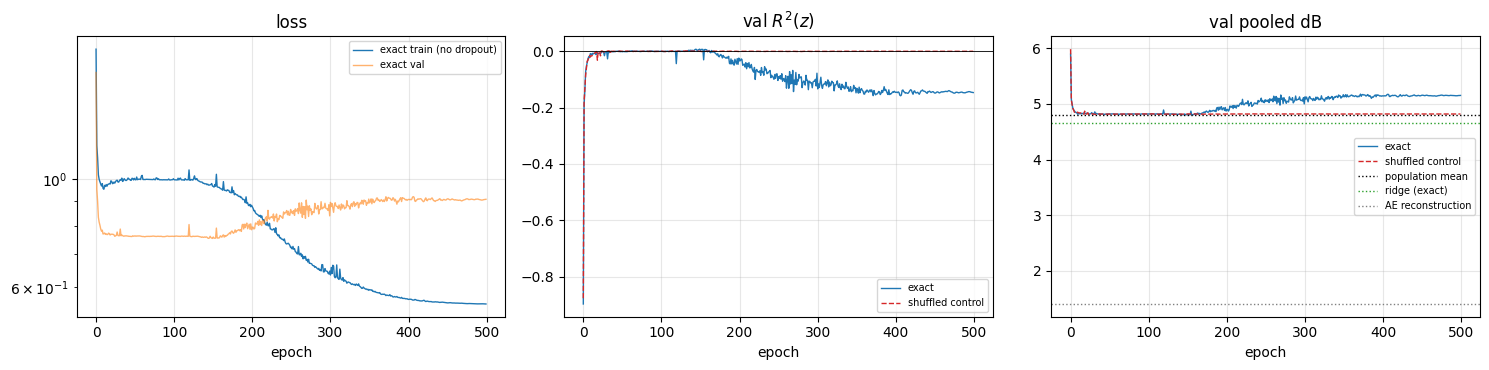

In [ ]:
# ==========================================================================
# Cell 9 — MLP（与 ridge 同一特征、同一输出空间）+ 打乱目标的对照。每个 epoch 记录，checkpoint 可续训
# ==========================================================================
def data_hash(X):
    h = hashlib.md5()
    for a in (X, Y, S['train'], S['val'], S['test']): h.update(np.ascontiguousarray(a).tobytes())
    return h.hexdigest()[:16]

def train_mlp(fs, X, tf, seed, shuffled=False):
    tag = f"{fs}_{'shuffled' if shuffled else f'seed{seed}'}"; path = os.path.join(OUT_DIR, f'ckpt_{tag}.pth')
    torch.manual_seed(seed); np.random.seed(seed)
    Xtr = torch.as_tensor(tf(X[S['train']]), dtype=torch.float32, device=device)
    Xva = torch.as_tensor(tf(X[S['val']]), dtype=torch.float32, device=device)
    Yt = Ytr
    if shuffled:                                       # 训练集内按人打乱（两只耳一起换），验证用真实目标
        subs = np.arange(len(Yt) // 2); p = np.random.default_rng(1000 + seed).permutation(subs)
        Yt = Yt[np.array([2 * p[k] + s for k in subs for s in (0, 1)])]
    Ttr = torch.as_tensor(PCA.forward(Yt), dtype=torch.float32, device=device)
    model_args = dict(d_in=int(Xtr.shape[1]), hidden=tuple(CFG['HIDDEN']), k=int(Ttr.shape[1]), p=float(CFG['DROPOUT']))
    model = MLP(**model_args).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG['LR'], weight_decay=CFG['WD'])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG['EPOCHS'], eta_min=CFG['LR_MIN'])
    meta = dict(tag=tag, feature_set=fs, seed=seed, shuffled=shuffled, data_hash=data_hash(X), model_args=model_args,
                cfg={k: CFG[k] for k in ('HIDDEN', 'DROPOUT', 'LR', 'WD', 'BATCH', 'LR_MIN', 'GRAD_CLIP', 'K_PC', 'SPLIT_SEED', 'VAL_FRAC')},
                blocks=tf.blocks, mesh_zip=MESH_ZIP_SHA256, features=FP)
    hist = dict(train_loss=[], train_loss_eval=[], train_r2=[], val_loss=[], val_r2=[], val_db=[], lr=[])
    best = dict(db=np.inf, state=None, epoch=0); start = 1
    if os.path.exists(path):
        ck = torch.load(path, map_location=device, weights_only=False)
        assert ck['meta'] == meta, f'{path} 与当前数据/配置不一致 —— 删除它，或换一个 OUT_DIR'
        model.load_state_dict(ck['state_last']); opt.load_state_dict(ck['optimizer']); hist = ck['hist']
        sched.load_state_dict(ck['scheduler']); sched.T_max = CFG['EPOCHS']
        best = dict(db=ck['best_val_db'], state=ck['state_best'], epoch=ck['best_epoch']); start = ck['epoch'] + 1
        torch.set_rng_state(ck['rng']['torch'].cpu())
        if torch.cuda.is_available() and ck['rng']['cuda'] is not None: torch.cuda.set_rng_state_all([r.cpu() for r in ck['rng']['cuda']])
        print(f"  [{tag}] 载入：已完成 {ck['epoch']} 个 epoch" + ('，不需要再训练' if start > CFG['EPOCHS'] else f"，从 epoch {start} 续训"))

    def save(ep):
        atomic_save(dict(
            meta=meta, epoch=ep, epochs_planned=CFG['EPOCHS'],
            state_last=model.state_dict(), state_best=best['state'], best_epoch=best['epoch'], best_val_db=best['db'],
            optimizer=opt.state_dict(), scheduler=sched.state_dict(), hist=hist,
            rng=dict(torch=torch.get_rng_state(), cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None),
            x_mean=tf.mx, x_std=tf.sx, x_w=tf.w, pca=dict(my=PCA.my, V=PCA.V, scale=PCA.scale), split=SPLIT,
            did=CFG['DID'], ffm_ckpt=os.path.basename(PATHS['ckpt']), saved=time.strftime('%Y-%m-%d %H:%M:%S')), path)

    for ep in range(start, CFG['EPOCHS'] + 1):
        model.train(); order = torch.randperm(len(Xtr), device=device); tl = 0.0
        for b in range(0, len(Xtr), CFG['BATCH']):
            j = order[b:b + CFG['BATCH']]
            loss = ((model(Xtr[j]) - Ttr[j]) ** 2).sum(1).mean()
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG['GRAD_CLIP']); opt.step(); tl += loss.item() * len(j)
        lr_now = opt.param_groups[0]['lr']; sched.step()
        model.eval()
        with torch.no_grad():
            Th = model(Xtr); Tva = model(Xva).cpu().numpy()
            tr_eval = float(((Th - Ttr) ** 2).sum(1).mean()); tr_r2 = float(1 - ((Th - Ttr) ** 2).sum() / ((Ttr - Ttr.mean(0)) ** 2).sum())
        Zva = PCA.inverse(Tva); db = float(np.sqrt(((decode(Zva) - Xva_h) ** 2).mean()))
        hist['train_loss'].append(tl / len(Xtr)); hist['train_loss_eval'].append(tr_eval); hist['train_r2'].append(tr_r2)
        hist['val_loss'].append(float(((Tva - PCA.forward(Yva)) ** 2).sum(1).mean()))
        hist['val_r2'].append(r2z(Zva, Yva, my_tr)); hist['val_db'].append(db); hist['lr'].append(lr_now)
        if db < best['db']: best = dict(db=db, state=copy.deepcopy(model.state_dict()), epoch=ep)
        if ep == 1 or ep % CFG['PRINT_EVERY'] == 0 or ep == CFG['EPOCHS']:
            print(f"  [{tag}] ep {ep:4d}/{CFG['EPOCHS']} | lr {lr_now:.1e} | train {hist['train_loss'][-1]:.3f} "
                  f"(no dropout {tr_eval:.3f}, R² {tr_r2:+.3f}) | val R² {hist['val_r2'][-1]:+.4f} | val dB {db:.3f} | best {best['db']:.3f} @ {best['epoch']}")
        if ep % CFG['SAVE_EVERY'] == 0 or ep == CFG['EPOCHS']: save(ep)
    model.load_state_dict(best['state']); model.eval()
    return model, hist, best['epoch']

def predict(model, tf, X):
    with torch.no_grad():
        return PCA.inverse(model(torch.as_tensor(tf(X), dtype=torch.float32, device=device)).cpu().numpy())

MLPS = {}
for fs in CFG['MLP_SETS']:
    X, blocks = build(fs); tf = BlockInput(X[S['train']], blocks)
    n_par = sum(p.numel() for p in MLP(X.shape[1], CFG['HIDDEN'], PCA.V.shape[1], CFG['DROPOUT']).parameters())
    print(f"\nMLP · {fs}：{X.shape[1]} → {CFG['HIDDEN']} → {PCA.V.shape[1]} 个主成分（全部）| {n_par:,} 个参数 | 训练耳 {len(S['train'])}")
    models, hists, preds = [], [], []
    for sd in CFG['SEEDS']:
        m, h, be = train_mlp(fs, X, tf, sd); models.append(m); hists.append(h); preds.append(predict(m, tf, X[S['val']]))
        print(f"  seed {sd}：最好 epoch {be} | val dB {min(h['val_db']):.3f}")
    ens = np.mean(preds, 0); ROWS[f'MLP · {fs} · seeds {CFG["SEEDS"]}'] = dict(r2=r2z(ens, Yva, my_tr), **ev(ens))
    MLPS[fs] = dict(models=models, hists=hists, tf=tf, n_params=n_par, best_epochs=[int(np.argmin(h['val_db'])) + 1 for h in hists])
fs = CFG['PRIMARY']; X, blocks = build(fs); tf = BlockInput(X[S['train']], blocks)
ms, hs, bs = train_mlp(fs, X, tf, 99, shuffled=True); ps = predict(ms, tf, X[S['val']])
ROWS[f'MLP · {fs} · shuffled targets (control)'] = dict(r2=r2z(ps, Yva, my_tr), **ev(ps))
ROWS['AE reconstruction (floor)'] = dict(r2=1.0, **REC)
show(ROWS, f"VALIDATION — 全部（{S['n_sub']['val']} 人 / {len(S['val'])} 只耳）")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for fs_, R_ in MLPS.items():
    for h in R_['hists']:
        ax[0].plot(h['train_loss_eval'], lw=1, label=f'{fs_} train (no dropout)'); ax[0].plot(h['val_loss'], lw=1, alpha=.6, label=f'{fs_} val')
        ax[1].plot(h['val_r2'], lw=1, label=fs_); ax[2].plot(h['val_db'], lw=1, label=fs_)
ax[1].plot(hs['val_r2'], c='C3', ls='--', lw=1, label='shuffled control'); ax[2].plot(hs['val_db'], c='C3', ls='--', lw=1, label='shuffled control')
for y, c, lab in ((BASE['db'], 'k', 'population mean'), (ROWS[f"ridge · {CFG['PRIMARY']}"]['db'], 'C2', 'ridge (exact)'), (REC['db'], 'grey', 'AE reconstruction')):
    ax[2].axhline(y, c=c, lw=1, ls=':', label=lab)
ax[0].set_yscale('log'); ax[0].set_title('loss'); ax[1].axhline(0, c='k', lw=.6); ax[1].set_title('val $R^2(z)$'); ax[2].set_title('val pooled dB')
for a in ax: a.set_xlabel('epoch'); a.grid(alpha=.3); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'mlp_curves.png'), dpi=150); plt.show()

In [ ]:
# ==========================================================================
# Cell 10 — 事先定好的读数（按人配对 bootstrap）· 停止规则 · 导出
# ==========================================================================
SUBJ_VA = np.array([r // 2 for r in S['val']]); US = np.unique(SUBJ_VA)
rng_b = np.random.default_rng(0); BOOT = [np.concatenate([np.flatnonzero(SUBJ_VA == u) for u in rng_b.choice(US, len(US))]) for _ in range(CFG['N_BOOT'])]
def paired(a, b):
    """pooled dB(a) − pooled dB(b)，负数 = a 更好；95% 区间按人重采样"""
    ea, eb = ROWS[a]['ear_mse'], ROWS[b]['ear_mse']
    d = np.sqrt(ea.mean()) - np.sqrt(eb.mean()); bt = [np.sqrt(ea[i].mean()) - np.sqrt(eb[i].mean()) for i in BOOT]
    return dict(a=a, b=b, delta_db=float(d), ci=[float(np.percentile(bt, 2.5)), float(np.percentile(bt, 97.5))])
P_ = CFG['PRIMARY']; rp = f'ridge · {P_}'
CMP = [paired(rp, f'ridge · mc20k_s{k}') for k in CFG['MC_SEEDS'] if f'ridge · mc20k_s{k}' in ROWS]
CMP += [paired(rp, f'ridge · {x}') for x in ('exact_colweight', 'exact_M1024', 'exact+normals') if f'ridge · {x}' in ROWS]
CMP += [paired(k, rp) for k in ROWS if k.startswith('MLP') and 'shuffled' not in k]
CMP += [paired(k, 'population mean (train ears)') for k in ROWS if k.startswith(('ridge', 'MLP'))]
print(f"{'a':46s}{'b':32s}{'Δ dB (a − b)':>13s}   95% CI（按人）")
for c in CMP: print(f"{c['a']:46s}{c['b']:32s}{c['delta_db']:+13.3f}   [{c['ci'][0]:+.3f}, {c['ci'][1]:+.3f}]")

model_rows = {k: r for k, r in ROWS.items() if k.startswith(('ridge', 'MLP')) and 'shuffled' not in k}
best = max(model_rows, key=lambda k: model_rows[k]['r2'])
print(f"\n最好的模型行：{best} —— val R²(z) {model_rows[best]['r2']:+.4f}，收回 {model_rows[best]['recovered']:.1%}，"
      f"{model_rows[best]['db']:.3f} dB（人群均值 {BASE['db']:.3f}，AE 重建 {REC['db']:.3f}）")
if model_rows[best]['r2'] < CFG['STOP_R2']:
    print(f"停止规则（所有模型行 val R²(z) < {CFG['STOP_R2']}）：★ 触发 —— 在完整网格、无采样的输入上结论不变：几何 → z 可检测、不可用")
else:
    print(f"停止规则：未触发 —— {best} 的 val R²(z) ≥ {CFG['STOP_R2']}。先看它对随机采样版本的配对差，再决定是否动用测试集")

clean = lambda r: {k: v for k, v in r.items() if k != 'ear_mse'}
out = dict(cfg={k: v for k, v in CFG.items() if k != 'ALPHA_REL'}, mesh_zip_sha256=MESH_ZIP_SHA256, features=FP,
           pack_info=INFO, n_subjects=S['n_sub'], split=SPLIT, sampling_noise=NOISE, ridge=RIDGE,
           val={k: clean(r) for k, r in ROWS.items()}, paired=CMP, best=best,
           mlp={fs: dict(n_params=R_['n_params'], best_epochs=R_['best_epochs']) for fs, R_ in MLPS.items()})
json.dump(out, open(os.path.join(OUT_DIR, 'results.json'), 'w'), indent=1, ensure_ascii=False, default=float)
print(f'-> {OUT_DIR}/results.json, mlp_curves.png')

a                                             b                                Δ dB (a − b)   95% CI（按人）
ridge · exact                                 ridge · mc20k_s0                       -0.003   [-0.009, +0.003]
ridge · exact                                 ridge · mc20k_s1                       +0.002   [-0.005, +0.009]
ridge · exact                                 ridge · mc20k_s2                       -0.002   [-0.011, +0.008]
ridge · exact                                 ridge · exact_colweight                -0.065   [-0.101, -0.031]
ridge · exact                                 ridge · exact_M1024                    +0.003   [-0.004, +0.009]
ridge · exact                                 ridge · exact+normals                  -0.019   [-0.042, +0.002]
MLP · exact · seeds [0]                       ridge · exact                          +0.156   [+0.079, +0.231]
ridge · exact                                 population mean (train ears)           -0.147   [-0.225, -0.067]
ridge ·

In [ ]:
# ==========================================================================
# Cell 11 — ★ TEST：36 个锁定受试者，只运行一次（与 FFM_3_5 共用标记）
# 先在 PROJECT_LOG §9C 3a 决定测试集用在哪个模型上；默认评估主特征上的 ridge 与 MLP，α / epoch 都已在验证集上冻结
# ==========================================================================
TEST = None
if not CFG['RUN_TEST'] or CFG['SMOKE_N']:
    print('RUN_TEST = False —— 测试集未读取')
else:
    guard_test()
    Xte_h = load_partition(S['test']); side_te = SIDE[S['test']]; Yte = Y[S['test']]
    base = hrtf_metrics(np.broadcast_to(MU, Xte_h.shape).astype(np.float32), Xte_h, side_te)
    rec = hrtf_metrics(decode(Yte), Xte_h, side_te)
    X, blocks = build(P_); tf = BlockInput(X[S['train']], blocks)
    f, _, _ = ridge_val(tf(X[S['train']]), Ytr, tf(X[S['val']]), Yva, [RIDGE[P_]['alpha_rel']])
    ens = np.mean([predict(m, MLPS[P_]['tf'], X[S['test']]) for m in MLPS[P_]['models']], 0)
    TEST = {'population mean (train ears)': dict(r2=0.0, **base)}
    for k, Z in ((f'ridge · {P_}', f(tf(X[S['test']]))), (f'MLP · {P_}', ens)):
        TEST[k] = dict(r2=r2z(Z, Yte, my_tr), **hrtf_metrics(decode(Z), Xte_h, side_te, base['db'], rec['db']))
    TEST['AE reconstruction (floor)'] = dict(r2=1.0, **rec)
    show(TEST, f"TEST（{S['n_sub']['test']} 人，第一次也是唯一一次）")
    rec_ = dict(time=time.strftime('%Y-%m-%d %H:%M:%S'), notebook='FFM_3_6', rows={k: clean(r) for k, r in TEST.items()})
    for p in (TEST_MARKS[0], TEST_MARKS[2]):
        os.makedirs(os.path.dirname(p), exist_ok=True); json.dump(rec_, open(p, 'w'), indent=1, default=float)
    print('已记录 —— 这个测试集现在已经用过了（FFM_3_5 的 TEST 格也会拒绝）')

RUN_TEST = False —— 测试集未读取


## 读结果之前
1. **「完整网格」在这里的意思**：每个三角形都精确地进入特征（没有采样），源文件逐字节可追溯。它不等于「把网格本身喂给网络」——
   任何回归器都需要一个固定长度的描述；本 notebook 检查的是这个描述加大（M = 1024）、加朝向（法向）以后是否改变结论。
2. **Cell 7** 应当重现审计 4.1 的量级（MC vs MC 约 12–23%），并且精确特征把这一项变成 0。
   如果 ridge · exact 与 ridge · mc20k 的配对差在 0 附近，采样噪声就不是 3_5 失败的原因。
3. **oracle 一行**是「完美预测、但只能落在训练主成分空间里」能达到的上限；MLP 与 ridge 现在都在这个空间里。
4. α 和 epoch 都在验证集上选：验证分数偏乐观。负结论因此是保守的；正结论必须先过测试集。
5. 仍然存在的限制：SONICOM 的预处理网格（已平滑）、仿真给出的耳道位置、有限描述符。写结论时一并写出。